<a href="https://colab.research.google.com/github/ncbx666/architecture-classification/blob/main/architectural_style_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json
mv: cannot move '/content/kaggle.json' to '/root/.config/kaggle/': Not a directory


In [ ]:
!mv /content/kaggle.json /root/.config/kaggle/

In [ ]:
import kaggle
from fastai.vision.all import *

## Download dataset from Kaggle

In [ ]:
# Скачивание датасета
kaggle.api.dataset_download_files("dumitrux/architectural-styles-dataset", path=".", unzip=True)

# Создание DataLoaders
dls = ImageDataLoaders.from_folder(
    path="architectural-styles-dataset",
    valid_pct=0.2,
    item_tfms=Resize(224)
)

Dataset URL: https://www.kaggle.com/datasets/dumitrux/architectural-styles-dataset


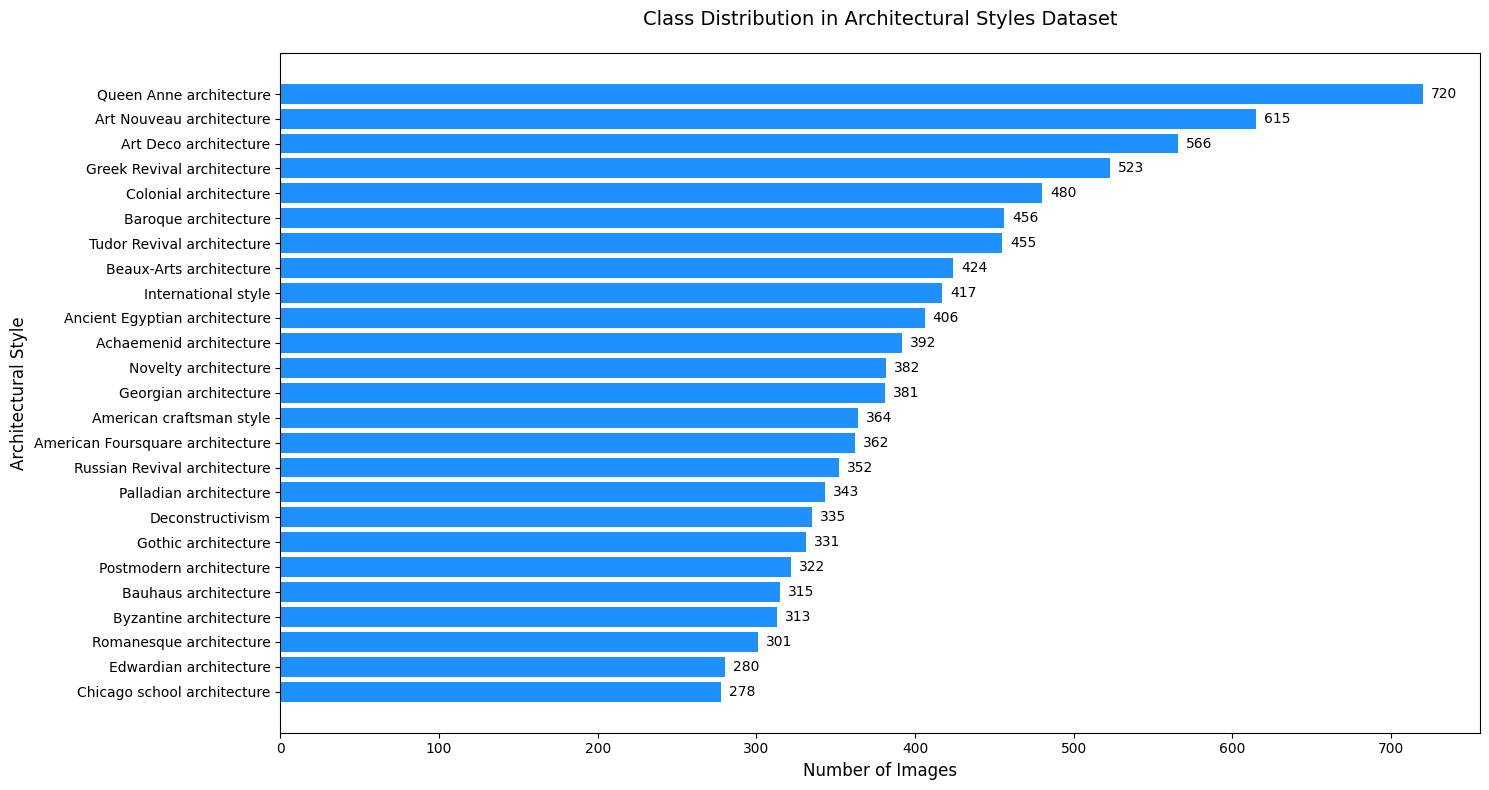


Подробная статистика:
             Architectural Style  Number of Images
         Queen Anne architecture               720
        Art Nouveau architecture               615
           Art Deco architecture               566
      Greek Revival architecture               523
           Colonial architecture               480
            Baroque architecture               456
      Tudor Revival architecture               455
         Beaux-Arts architecture               424
             International style               417
   Ancient Egyptian architecture               406
         Achaemenid architecture               392
            Novelty architecture               382
           Georgian architecture               381
        American craftsman style               364
American Foursquare architecture               362
    Russian Revival architecture               352
          Palladian architecture               343
                Deconstructivism               335
        

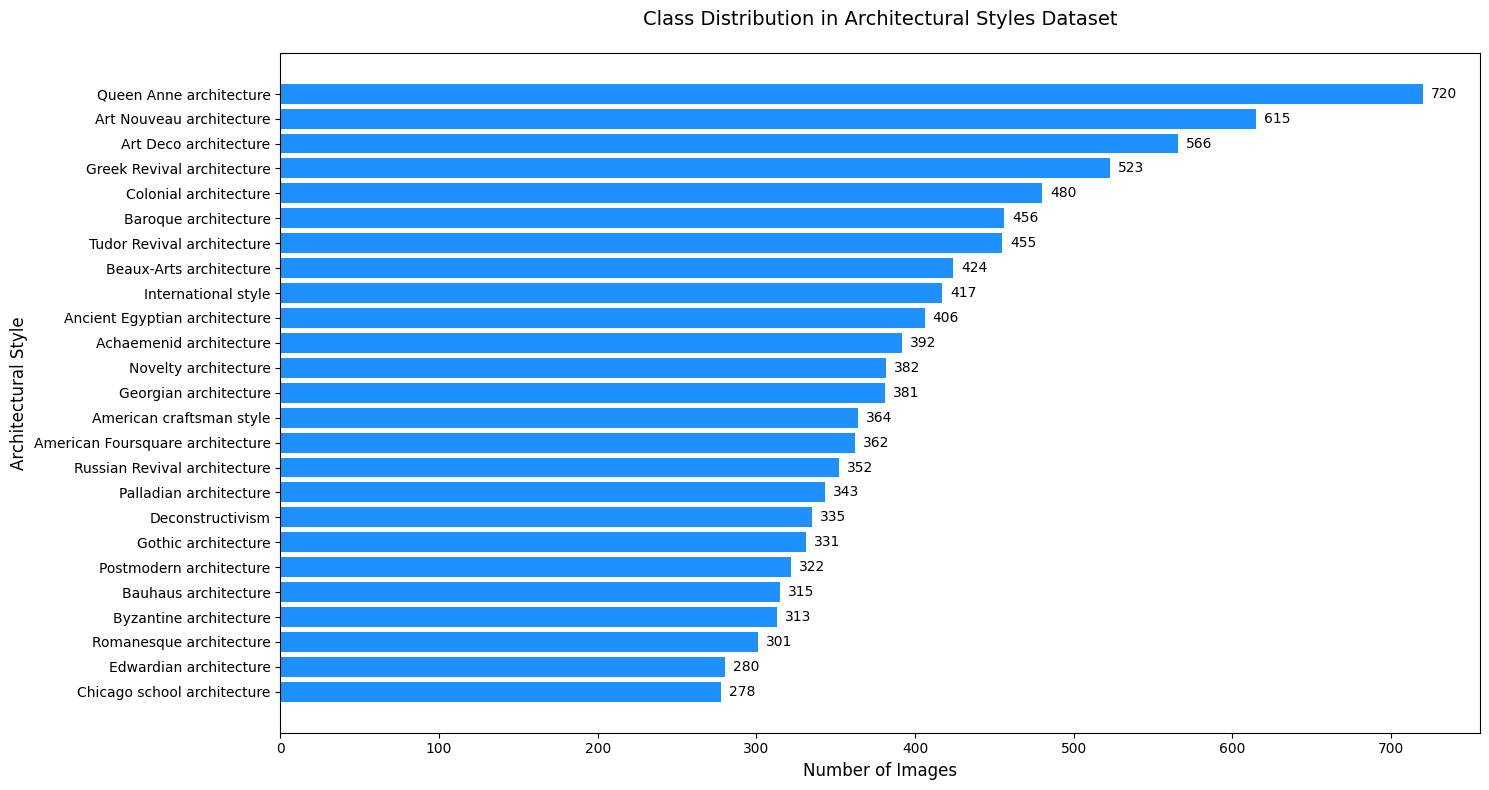


Подробная статистика:
             Architectural Style  Number of Images
         Queen Anne architecture               720
        Art Nouveau architecture               615
           Art Deco architecture               566
      Greek Revival architecture               523
           Colonial architecture               480
            Baroque architecture               456
      Tudor Revival architecture               455
         Beaux-Arts architecture               424
             International style               417
   Ancient Egyptian architecture               406
         Achaemenid architecture               392
            Novelty architecture               382
           Georgian architecture               381
        American craftsman style               364
American Foursquare architecture               362
    Russian Revival architecture               352
          Palladian architecture               343
                Deconstructivism               335
        

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Путь к датасету
path = Path("architectural-styles-dataset")

# Собираем статистику по классам
class_counts = {}
for style_dir in path.iterdir():
    if style_dir.is_dir():
        num_images = len(list(style_dir.glob("*.*")))  # Считаем все файлы
        class_counts[style_dir.name] = num_images

# Создаем DataFrame
df = pd.DataFrame({
    "Architectural Style": class_counts.keys(),
    "Number of Images": class_counts.values()
}).sort_values("Number of Images", ascending=False)

# Визуализация
plt.figure(figsize=(15, 8))
bars = plt.barh(df["Architectural Style"], df["Number of Images"], color="dodgerblue")
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Architectural Style", fontsize=12)
plt.title("Class Distribution in Architectural Styles Dataset", fontsize=14, pad=20)
plt.gca().invert_yaxis()  # Самый частый класс сверху

# Добавляем аннотации с количеством
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f"{int(width)}",
             ha="left", va="center")

plt.tight_layout()
plt.show()

# Выводим таблицу
print("\nПодробная статистика:")
print(df.to_string(index=False))


# Собираем статистику по классам
class_counts = {}
for style_dir in path.iterdir():
    if style_dir.is_dir():
        num_images = len(list(style_dir.glob("*.*")))  # Считаем все файлы
        class_counts[style_dir.name] = num_images

# Создаем DataFrame
df = pd.DataFrame({
    "Architectural Style": class_counts.keys(),
    "Number of Images": class_counts.values()
}).sort_values("Number of Images", ascending=False)

# Визуализация
plt.figure(figsize=(15, 8))
bars = plt.barh(df["Architectural Style"], df["Number of Images"], color="dodgerblue")
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Architectural Style", fontsize=12)
plt.title("Class Distribution in Architectural Styles Dataset", fontsize=14, pad=20)
plt.gca().invert_yaxis()  # Самый частый класс сверху

# Добавляем аннотации с количеством
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f"{int(width)}",
             ha="left", va="center")

plt.tight_layout()
plt.show()

# Выводим таблицу
print("\nПодробная статистика:")
print(df.to_string(index=False))

## Training: resnet50

### Training

In [ ]:
from collections import defaultdict
import numpy as np
import torch

# 1. Собираем статистику по классам в обучающей выборке
class_counts = defaultdict(int)
for _, label in dls.train_ds:
    class_counts[dls.vocab[label]] += 1

# 2. Преобразуем в массив в порядке vocab
class_counts = np.array([class_counts[cls] for cls in dls.vocab])

# 3. Рассчитываем веса (обратно пропорционально количеству образцов)
class_weights = 1. / class_counts
class_weights = class_weights / class_weights.sum()  # Нормализуем
class_weights = torch.tensor(class_weights, dtype=torch.float32)

print("Распределение классов:")
for cls, count, weight in zip(dls.vocab, class_counts, class_weights):
    print(f"{cls}: {count} samples, weight: {weight:.4f}")

# 4. Создаем взвешенную функцию потерь
weighted_loss = torch.nn.CrossEntropyLoss(weight=class_weights.to(dls.device))


Распределение классов:
Achaemenid architecture: 318 samples, weight: 0.0386
American Foursquare architecture: 293 samples, weight: 0.0419
American craftsman style: 294 samples, weight: 0.0417
Ancient Egyptian architecture: 316 samples, weight: 0.0388
Art Deco architecture: 459 samples, weight: 0.0267
Art Nouveau architecture: 490 samples, weight: 0.0250
Baroque architecture: 370 samples, weight: 0.0332
Bauhaus architecture: 252 samples, weight: 0.0487
Beaux-Arts architecture: 323 samples, weight: 0.0380
Byzantine architecture: 244 samples, weight: 0.0503
Chicago school architecture: 247 samples, weight: 0.0497
Colonial architecture: 361 samples, weight: 0.0340
Deconstructivism: 283 samples, weight: 0.0433
Edwardian architecture: 222 samples, weight: 0.0553
Georgian architecture: 312 samples, weight: 0.0393
Gothic architecture: 256 samples, weight: 0.0479
Greek Revival architecture: 404 samples, weight: 0.0304
International style: 337 samples, weight: 0.0364
Novelty architecture: 320 sa

In [ ]:
learn = vision_learner(
    dls,
    resnet50,
    loss_func=weighted_loss,
    metrics=[accuracy, error_rate, F1Score(average='weighted')],  # Добавляем F1-score
    wd=1e-1
)

Начинаем обучение...


epoch,train_loss,valid_loss,accuracy,error_rate,f1_score,time
0,3.686790,2.444974,0.293769,0.706231,0.271529,01:39
1,2.815107,1.857230,0.439664,0.560336,0.418830,01:40
2,2.202865,1.522931,0.539565,0.460435,0.525718,01:39
3,1.789574,1.370436,0.575668,0.424332,0.566351,01:42
4,1.519725,1.301918,0.604352,0.395648,0.600083,01:39
5,1.319701,1.234860,0.628091,0.371909,0.623118,01:39
6,1.115484,1.208361,0.636004,0.363996,0.629507,01:38
7,1.022820,1.176440,0.647873,0.352127,0.645894,01:38
8,0.927988,1.182655,0.667656,0.332344,0.667090,01:38
9,0.838019,1.132011,0.663699,0.336301,0.662297,01:40


epoch,train_loss,valid_loss,accuracy,error_rate,f1_score,time
0,3.686790,2.444974,0.293769,0.706231,0.271529,01:39
1,2.815107,1.857230,0.439664,0.560336,0.418830,01:40
2,2.202865,1.522931,0.539565,0.460435,0.525718,01:39
3,1.789574,1.370436,0.575668,0.424332,0.566351,01:42
4,1.519725,1.301918,0.604352,0.395648,0.600083,01:39
5,1.319701,1.234860,0.628091,0.371909,0.623118,01:39
6,1.115484,1.208361,0.636004,0.363996,0.629507,01:38
7,1.022820,1.176440,0.647873,0.352127,0.645894,01:38
8,0.927988,1.182655,0.667656,0.332344,0.667090,01:38
9,0.838019,1.132011,0.663699,0.336301,0.662297,01:40


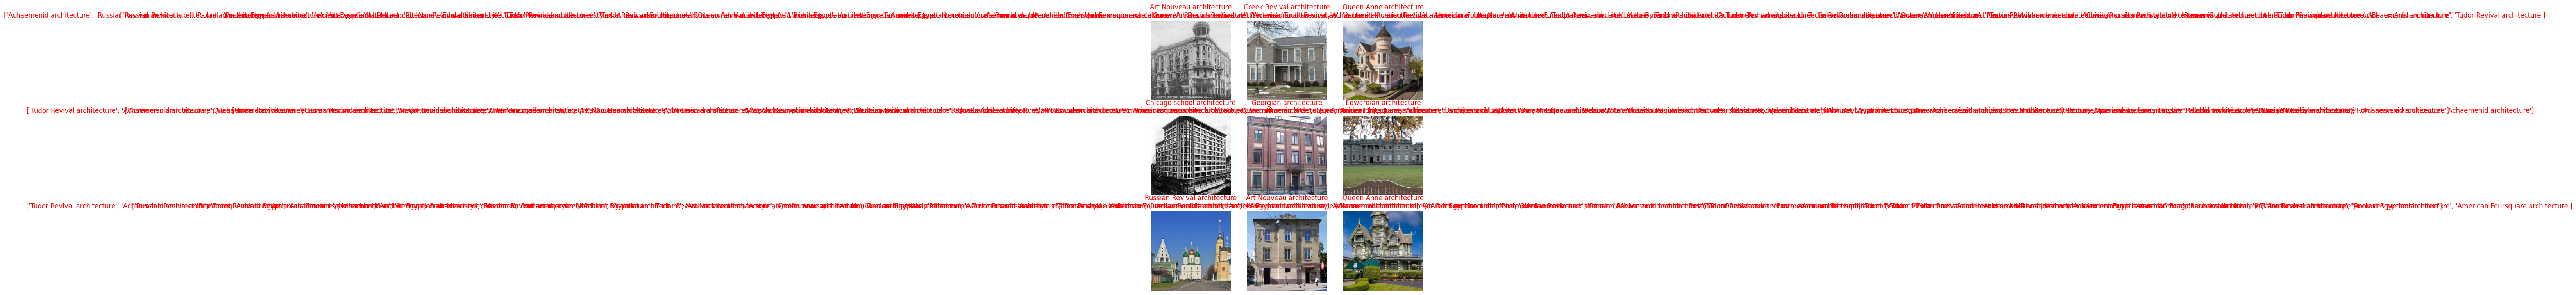

In [ ]:
# 5. Обучение (с прогрессом)
print("Начинаем обучение...")
learn.fit_one_cycle(50)
learn.show_results()  # показываем результаты

In [ ]:
learn.save('stage-1-resnet50-6cycles')

Path('architectural-styles-dataset/models/stage-1-resnet50-6cycles.pth')

### Unfreezing, fine-tuning and learning rates

Поиск оптимального learning rate...


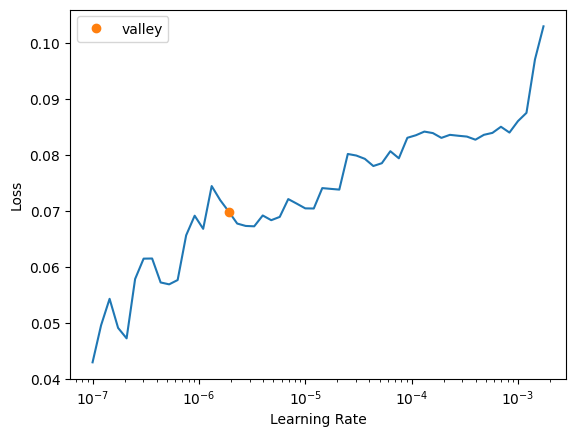

In [ ]:
# 1. Размораживаем все слои модели
learn.unfreeze()

# 2. Подбираем оптимальные learning rates
print("Поиск оптимального learning rate...")
lr_find_result = learn.lr_find()
plt.show()


Начинаем дообучение модели...


epoch,train_loss,valid_loss,accuracy,error_rate,f1_score,time
0,0.078461,1.186940,0.722057,0.277943,0.718260,01:45
1,0.073876,1.174091,0.721563,0.278437,0.718512,01:50
2,0.071848,1.172192,0.721563,0.278437,0.718517,01:47
3,0.079786,1.170620,0.720079,0.279921,0.716900,01:43
4,0.079890,1.173248,0.721563,0.278437,0.719000,01:43
5,0.070035,1.198578,0.722057,0.277943,0.718545,01:44
6,0.076003,1.191676,0.722057,0.277943,0.718550,01:44
7,0.077840,1.168333,0.726014,0.273986,0.722756,01:46
8,0.068225,1.164157,0.721563,0.278437,0.718385,01:44
9,0.084660,1.171056,0.726508,0.273492,0.723336,01:44


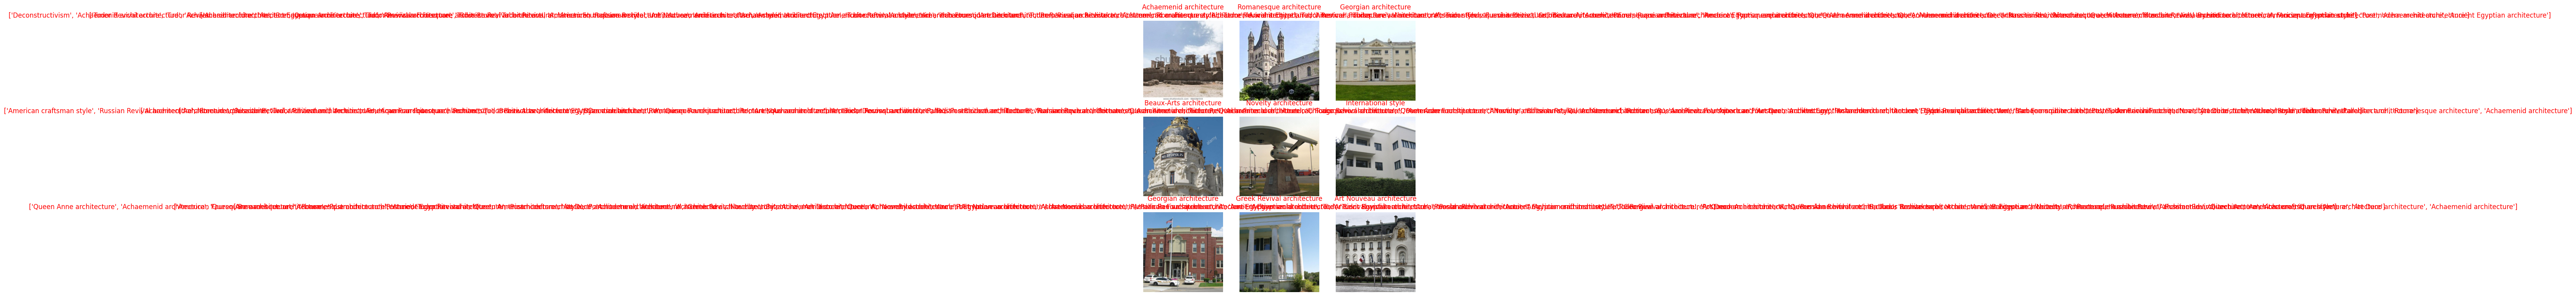

In [ ]:
# 4. Дообучение с выбранными learning rates
print("\nНачинаем дообучение модели...")
learn.fit_one_cycle(
    50,  # количество эпох
    lr_max=0.82*1e-5,  # диапазон learning rates
    wd=1e-1,  # weight decay
)

# 5. Показываем результаты
learn.show_results()

In [ ]:
learn.save('stage-2-resnet50', return_path=True)

# Сохранение модели


In [ ]:
# Сохраняет модель + веса + vocab (классы)
learn.export('architecture_style.pkl')  # автоматически сохраняет в models/

# Results resnet50

In [ ]:
interp = ClassificationInterpretation.from_learner(learn)

In [ ]:
interp.most_confused(min_val=3)

[('International style', 'Postmodern architecture', 7),
 ('International style', 'Art Deco architecture', 4),
 ('Tudor Revival architecture', 'American craftsman style', 4),
 ('American Foursquare architecture', 'American craftsman style', 3),
 ('Baroque architecture', 'Romanesque architecture', 3)]

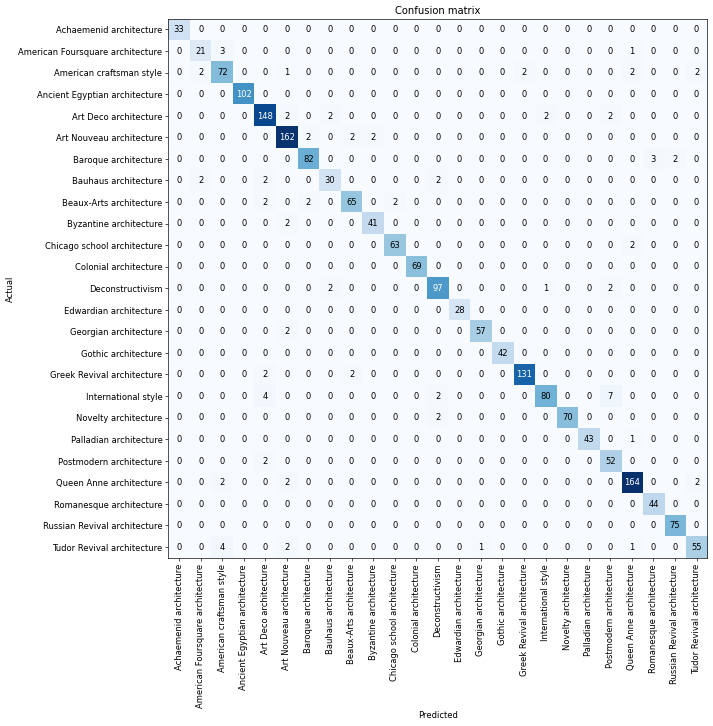

In [ ]:
interp.plot_confusion_matrix(figsize=(12,12), dpi=60)

Duplicate images on top losses, because of data augmentation

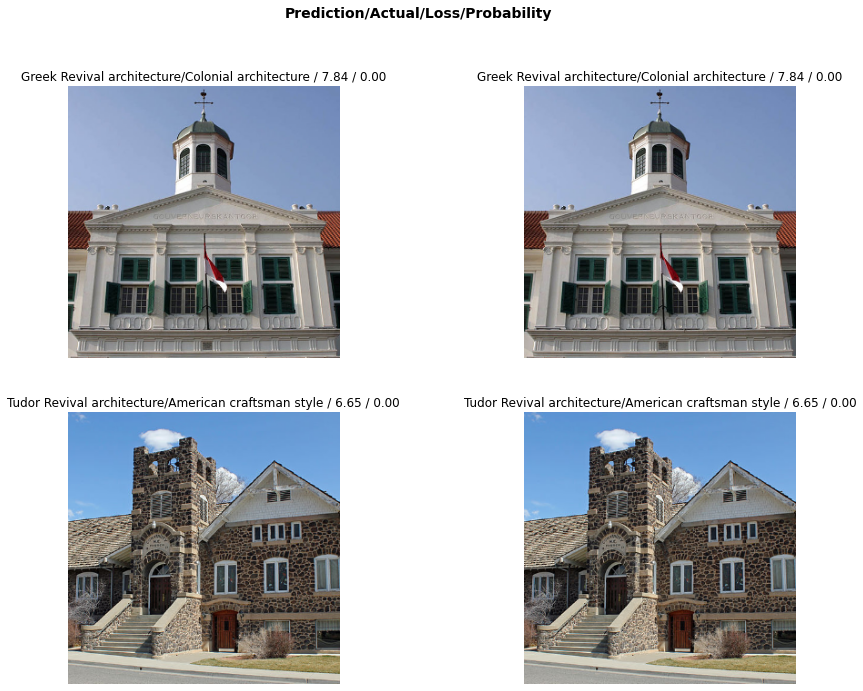

In [ ]:
interp.plot_top_losses(4, figsize=(15,11))

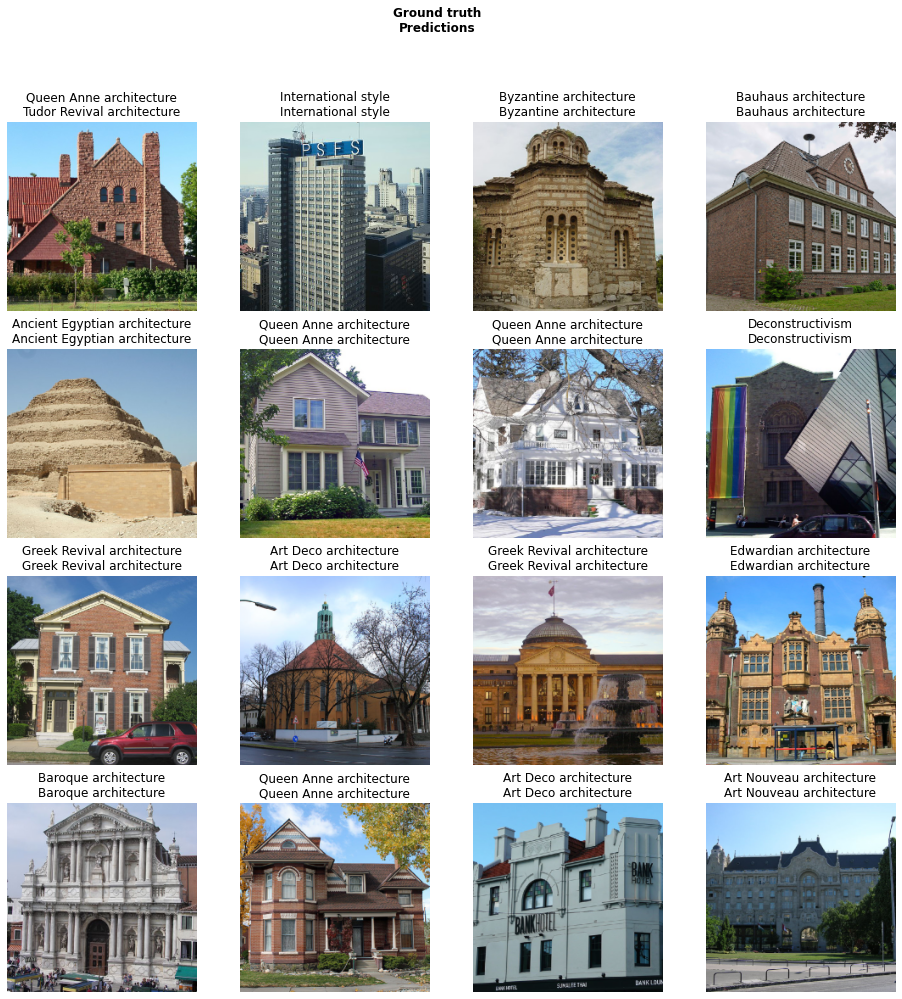

In [ ]:
learn.show_results(rows=4)

In [ ]:
img = open_image(path/'arcDataset'/'Bauhaus architecture'/'46_800px-Friedrichshafen_Hafenbahnhof_Zeppelinmuseum.jpg')
# img

In [ ]:
pred_class,pred_idx,outputs = learn.predict(img)
data.classes[int(pred_class)]

'Art Deco architecture'

In [ ]:
outputs

tensor([4.8131e-05, 4.0115e-04, 1.5859e-04, 1.8332e-05, 9.1667e-01, 2.8412e-04,
        6.4029e-06, 1.6311e-02, 1.4279e-04, 2.3726e-05, 3.7191e-04, 4.3844e-05,
        2.8516e-03, 1.0721e-04, 1.3770e-05, 5.1941e-05, 4.0738e-05, 6.0796e-02,
        2.3134e-04, 1.5984e-06, 1.3584e-03, 1.8242e-06, 2.2416e-05, 4.1732e-05,
        5.2506e-06])